# TrustRestore

## Outputs
- Controlled synthetic degradation for valid PSNR/SSIM
- Lightweight U-Net restoration
- Correct Monte Carlo Dropout uncertainty
- Data, structural, and stability Trust Maps
- Trust-vs-error plots and correlation CSV
- Ablation study and paper-ready figures
- Optional Gradio web UI for uploading any image



In [ ]:
!pip -q install opencv-python-headless scikit-image matplotlib tqdm pandas gradio

import os, random, zipfile
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import gradio as gr
from tqdm.auto import tqdm
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from google.colab import files

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = 'cuda' if torch.cuda.is_available() else 'cpu'
for folder in ['paper_figures','paper_outputs','research_analysis','saved_model']:
    os.makedirs(folder, exist_ok=True)
print('Device:', device)

Device: cpu


In [ ]:
# Upload CLEAN images for controlled evaluation.
uploaded = files.upload()
image_paths = list(uploaded.keys())
if not image_paths:
    raise ValueError('Upload at least one image.')
print('Uploaded:', image_paths)

Saving image3.jpg to image3.jpg
Saving image2.jpg to image2.jpg
Saving image1.jpg to image1.jpg
Uploaded: ['image3.jpg', 'image2.jpg', 'image1.jpg']


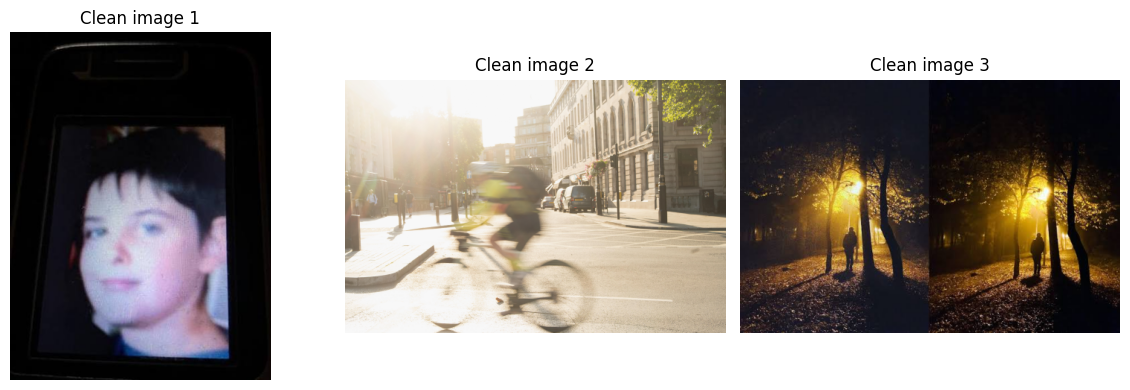

In [ ]:
MAX_SIZE = 512

def load_image(path):
    image = cv2.imread(path)
    if image is None:
        raise ValueError(f'Cannot read: {path}')
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w = image.shape[:2]
    scale = min(1.0, MAX_SIZE / max(h, w))
    if scale < 1:
        image = cv2.resize(image, (int(w*scale), int(h*scale)), interpolation=cv2.INTER_AREA)
    return image.astype(np.float32)/255.0

def show_images(images, titles, path=None, figsize=None, cmaps=None):
    plt.figure(figsize=figsize or (4*len(images),4))
    for i,(image,title) in enumerate(zip(images,titles),1):
        ax=plt.subplot(1,len(images),i)
        cmap=None if cmaps is None else cmaps[i-1]
        ax.imshow(np.clip(image,0,1),cmap=cmap,vmin=0 if cmap else None,vmax=1 if cmap else None)
        ax.set_title(title); ax.axis('off')
    plt.tight_layout()
    if path: plt.savefig(path,dpi=300,bbox_inches='tight')
    plt.show()

clean_images=[load_image(p) for p in image_paths]
show_images(clean_images,[f'Clean image {i+1}' for i in range(len(clean_images))], 'paper_figures/fig1_clean_inputs.png')

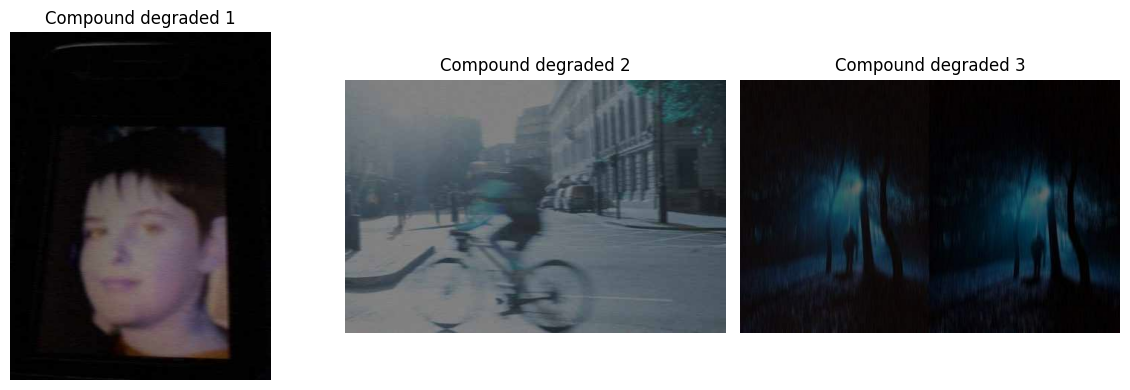

In [ ]:
# Synthetic compound degradation: low light + noise + motion blur + JPEG compression.
def compound_degrade(image, offset=0):
    rng=np.random.default_rng(SEED+offset)
    output=np.clip(image*rng.uniform(0.38,0.60),0,1)
    output=output+rng.normal(0,rng.uniform(0.02,0.05),output.shape).astype(np.float32)
    length=int(rng.integers(5,12)); kernel=np.zeros((length,length),np.float32)
    if rng.random()<0.5: kernel[length//2,:]=1/length
    else: kernel[:,length//2]=1/length
    output=cv2.filter2D(output,-1,kernel)
    ok, encoded=cv2.imencode('.jpg',np.clip(output*255,0,255).astype(np.uint8),[cv2.IMWRITE_JPEG_QUALITY,int(rng.integers(40,70))])
    if ok:
        output=cv2.imdecode(encoded,cv2.IMREAD_COLOR).astype(np.float32)/255.0
        output=cv2.cvtColor(output,cv2.COLOR_BGR2RGB)
    return np.clip(output,0,1)

degraded_images=[compound_degrade(im,i) for i,im in enumerate(clean_images)]
show_images(degraded_images,[f'Compound degraded {i+1}' for i in range(len(degraded_images))], 'paper_figures/fig2_compound_degraded.png')

Training:   0%|          | 0/300 [00:00<?, ?it/s]

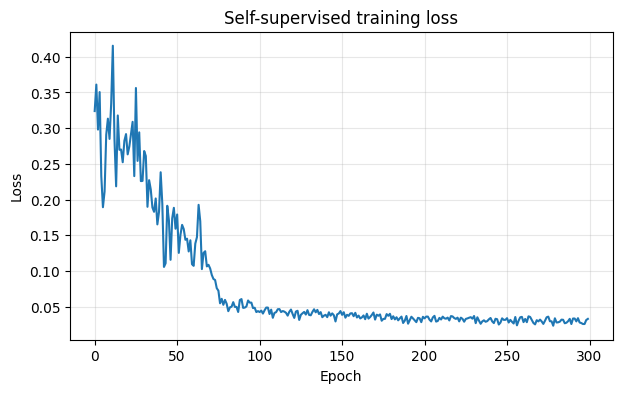

In [ ]:
class TrustUNet(nn.Module):
    def __init__(self, base=32, dropout=0.10):
        super().__init__()
        self.e1=nn.Sequential(nn.Conv2d(3,base,3,padding=1),nn.ReLU(),nn.Conv2d(base,base,3,padding=1),nn.ReLU())
        self.e2=nn.Sequential(nn.Conv2d(base,base*2,3,padding=1),nn.ReLU(),nn.Conv2d(base*2,base*2,3,padding=1),nn.ReLU())
        self.pool=nn.MaxPool2d(2)
        self.mid=nn.Sequential(nn.Conv2d(base*2,base*4,3,padding=1),nn.ReLU(),nn.Dropout2d(dropout),nn.Conv2d(base*4,base*4,3,padding=1),nn.ReLU())
        self.up2=nn.ConvTranspose2d(base*4,base*2,2,stride=2)
        self.d2=nn.Sequential(nn.Conv2d(base*4,base*2,3,padding=1),nn.ReLU(),nn.Conv2d(base*2,base*2,3,padding=1),nn.ReLU())
        self.up1=nn.ConvTranspose2d(base*2,base,2,stride=2)
        self.d1=nn.Sequential(nn.Conv2d(base*2,base,3,padding=1),nn.ReLU(),nn.Conv2d(base,base,3,padding=1),nn.ReLU())
        self.out=nn.Conv2d(base,3,1)
    def forward(self,x):
        a=self.e1(x); b=self.e2(self.pool(a)); m=self.mid(self.pool(b))
        d2=self.d2(torch.cat([self.up2(m),b],1)); d1=self.d1(torch.cat([self.up1(d2),a],1))
        return torch.sigmoid(self.out(d1))

PATCH=96; MASK_RATIO=0.08; EPOCHS=300; BATCH=8; LR=2e-4

def random_patch(image):
    h,w,_=image.shape; y=np.random.randint(0,max(1,h-PATCH+1)); x=np.random.randint(0,max(1,w-PATCH+1))
    patch=image[y:y+PATCH,x:x+PATCH]
    if patch.shape[:2] != (PATCH,PATCH): patch=cv2.resize(patch,(PATCH,PATCH))
    return patch

def train_model(images):
    net=TrustUNet().to(device); optimizer=torch.optim.AdamW(net.parameters(),lr=LR,weight_decay=1e-4)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS); history=[]
    for _ in tqdm(range(EPOCHS),desc='Training'):
        net.train(); patches=[]; masks=[]
        for _ in range(BATCH):
            patch=random_patch(random.choice(images)); patches.append(patch); masks.append((np.random.rand(PATCH,PATCH)<MASK_RATIO).astype(np.float32))
        x=torch.from_numpy(np.stack(patches)).permute(0,3,1,2).float().to(device)
        mask=torch.from_numpy(np.stack(masks)).unsqueeze(1).float().to(device)
        pred=net(x*(1-mask))
        masked=(torch.abs(pred-x)*mask).sum()/(mask.sum()*3+1e-8)
        edge=F.l1_loss(pred[:,:,:,1:]-pred[:,:,:,:-1],x[:,:,:,1:]-x[:,:,:,:-1])+F.l1_loss(pred[:,:,1:,:]-pred[:,:,:-1,:],x[:,:,1:,:]-x[:,:,:-1,:])
        loss=masked+0.15*edge
        optimizer.zero_grad(); loss.backward(); optimizer.step(); scheduler.step(); history.append(float(loss.detach().cpu()))
    return net,history

model,losses=train_model(degraded_images)
torch.save(model.state_dict(),'saved_model/trustrestore_v2.pth')
plt.figure(figsize=(7,4)); plt.plot(losses); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Self-supervised training loss'); plt.grid(alpha=.3)
plt.savefig('paper_figures/fig6_training_loss.png',dpi=300,bbox_inches='tight'); plt.show()

In [ ]:
MC_SAMPLES=20

def gradient(image):
    gray=cv2.cvtColor(np.clip(image,0,1).astype(np.float32),cv2.COLOR_RGB2GRAY)
    gx=cv2.Sobel(gray,cv2.CV_32F,1,0,ksize=3); gy=cv2.Sobel(gray,cv2.CV_32F,0,1,ksize=3)
    return np.sqrt(gx*gx+gy*gy)

def noise_sigma(image):
    gray=cv2.cvtColor((np.clip(image,0,1)*255).astype(np.uint8),cv2.COLOR_RGB2GRAY).astype(np.float32)/255
    hp=gray-cv2.GaussianBlur(gray,(3,3),0)
    return max(1e-3,1.4826*np.median(np.abs(hp-np.median(hp))))

def mc_predict(net,image,k=MC_SAMPLES):
    h,w,_=image.shape; ph=(4-h%4)%4; pw=(4-w%4)%4
    padded=np.pad(image,((0,ph),(0,pw),(0,0)),mode='reflect')
    x=torch.from_numpy(padded).permute(2,0,1).unsqueeze(0).float().to(device)
    preds=[]; net.train()  # Keep dropout ON for valid MC uncertainty.
    with torch.no_grad():
        for _ in range(k): preds.append(net(x)[0].permute(1,2,0).cpu().numpy()[:h,:w])
    net.eval(); preds=np.stack(preds)
    return np.clip(preds.mean(0),0,1),preds.var(0).mean(-1,keepdims=True)

def trust_map(observed,restored,var,use_data=True,use_structure=True,use_stability=True):
    eps=1e-8; sn=noise_sigma(observed); residual=np.abs(restored-observed).mean(-1,keepdims=True)
    data=np.exp(-(residual**2)/(2*sn**2+eps)) if use_data else np.ones_like(residual)
    serr=np.abs(gradient(restored)-gradient(observed))[...,None]; sg=max(1e-3,np.percentile(serr,75))
    structure=np.exp(-(serr**2)/(2*sg**2+eps)) if use_structure else np.ones_like(serr)
    stable=np.exp(-var/(np.percentile(var,95)+eps)) if use_stability else np.ones_like(var)
    trust=data*structure*stable; trust=(trust-trust.min())/(trust.max()-trust.min()+eps)
    return trust,data,structure,stable

def refine(restored,trust,threshold=0.45):
    low=(trust[...,0]<threshold).astype(np.uint8)*255; low=cv2.dilate(low,np.ones((3,3),np.uint8),iterations=1)
    bilateral=cv2.bilateralFilter((restored*255).astype(np.uint8),7,35,35).astype(np.float32)/255
    mask=(low/255.0)[...,None]
    return np.clip(restored*(1-mask)+bilateral*mask,0,1)

results=[]
for clean,degraded in zip(clean_images,degraded_images):
    restored,var=mc_predict(model,degraded); trust,data,structure,stable=trust_map(degraded,restored,var); refined=refine(restored,trust)
    results.append({'clean':clean,'degraded':degraded,'restored':restored,'var':var,'trust':trust,'data':data,'structure':structure,'stable':stable,'refined':refined})

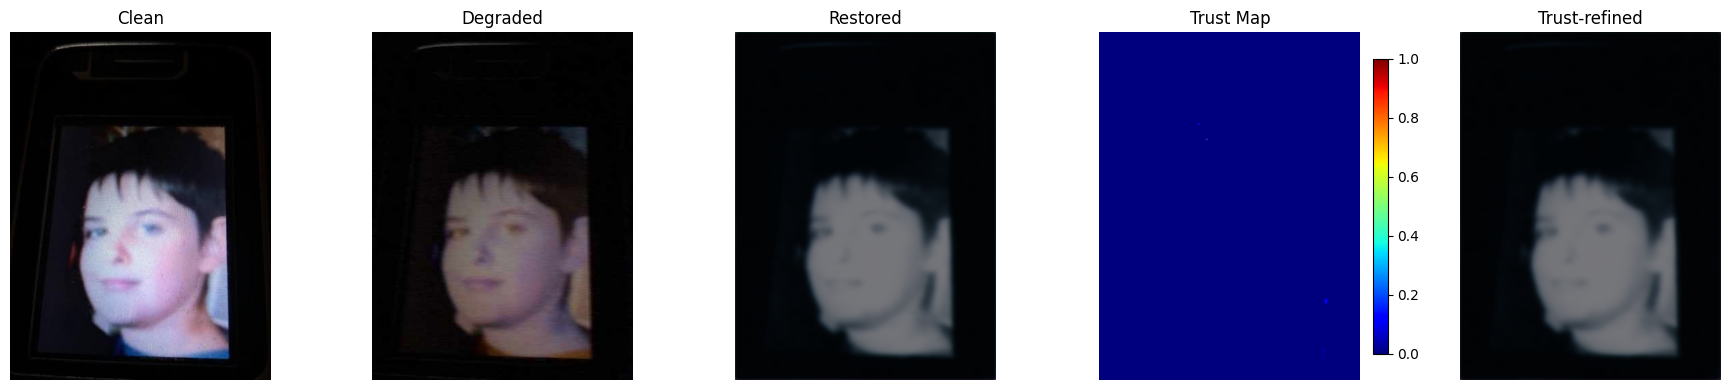

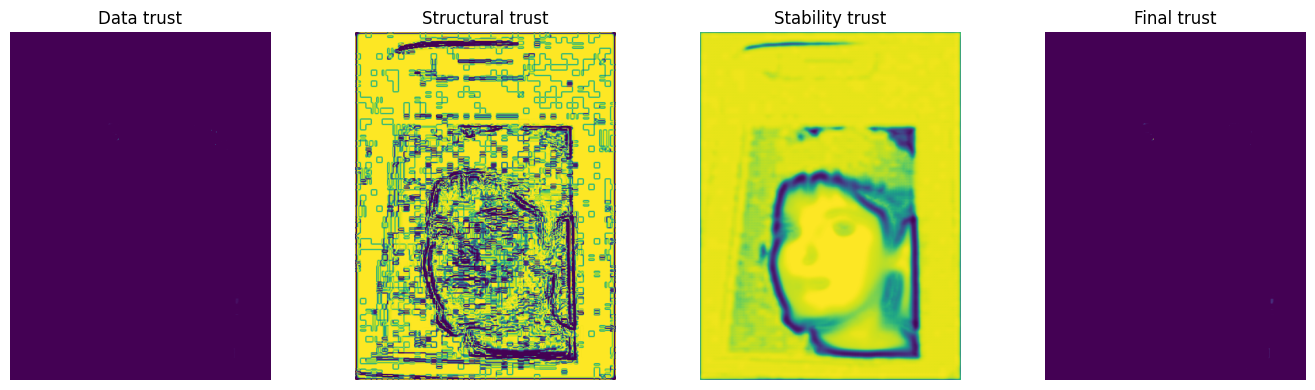

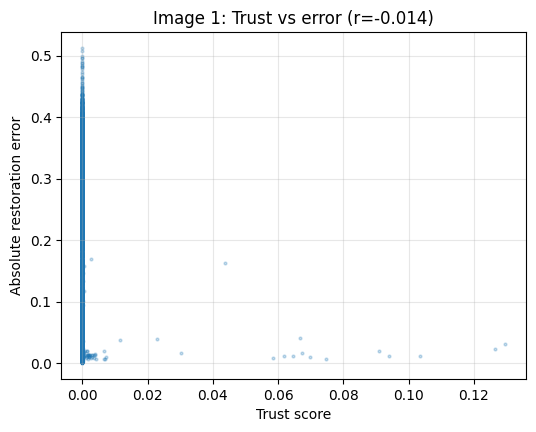

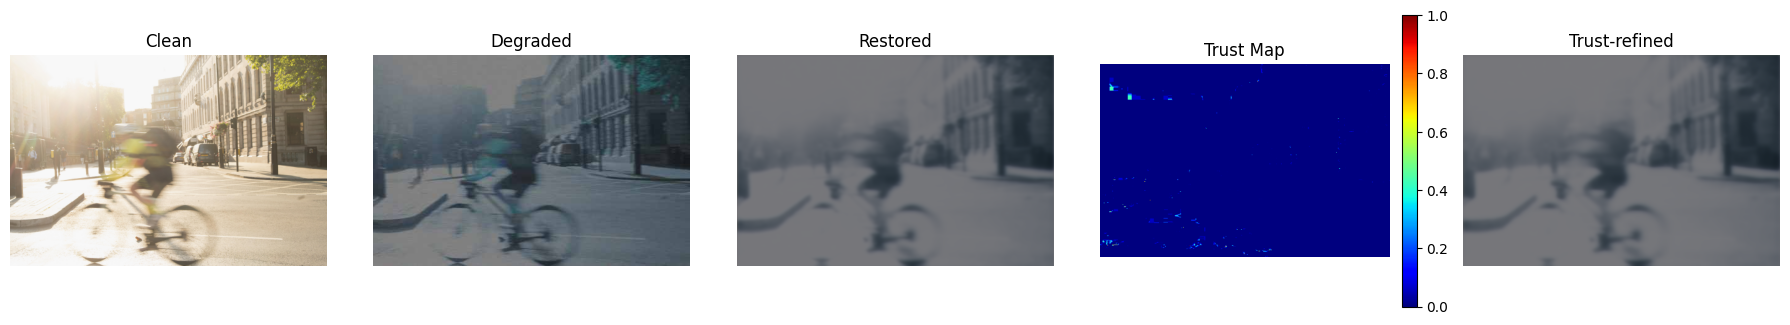

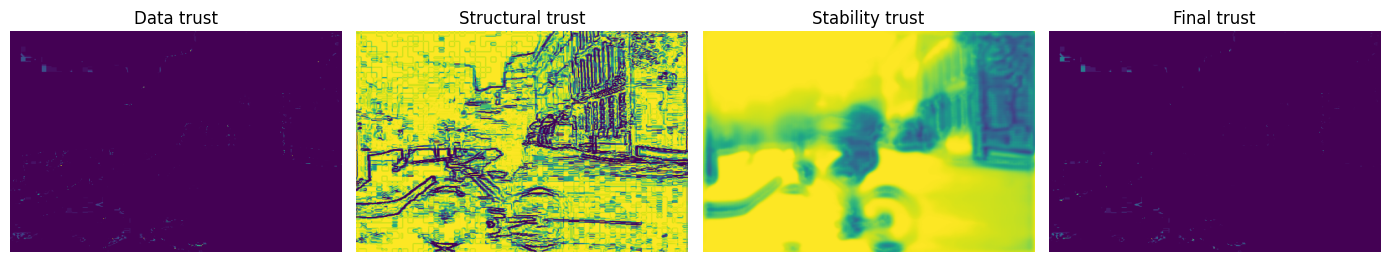

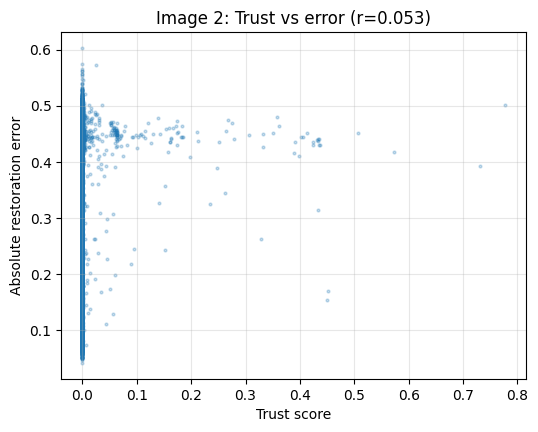

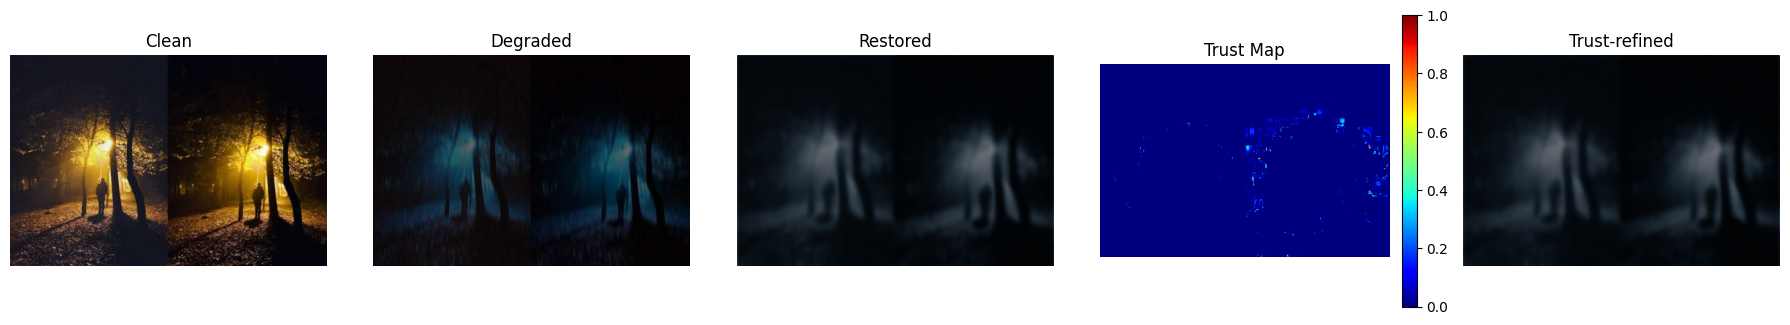

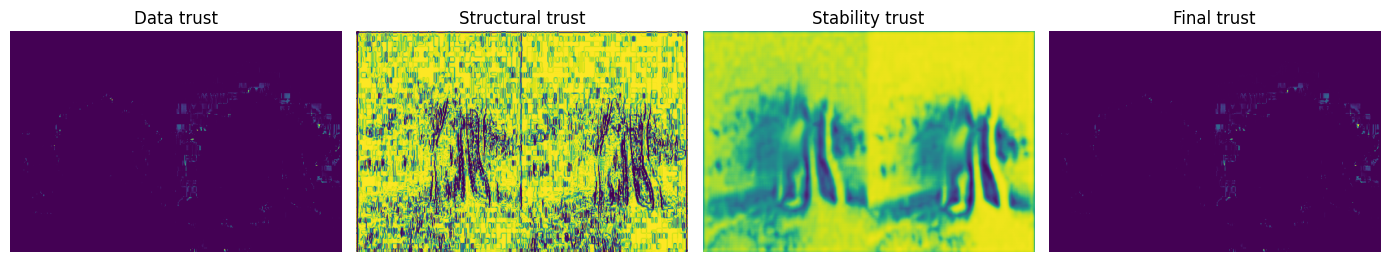

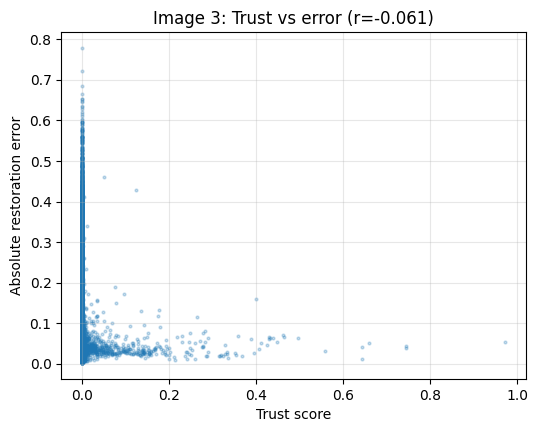

,Image,Method,PSNR_dB,SSIM,LaplacianSharpness
0,1,Degraded input,15.7682,0.7725,10.1923
1,1,Deep restoration,16.4223,0.6651,12.6165
2,1,Trust-refined,16.3618,0.6623,4.9268
3,2,Degraded input,8.5501,0.6097,50.8639
4,2,Deep restoration,9.0742,0.5168,5.4004
5,2,Trust-refined,9.0187,0.5085,2.7127
6,3,Degraded input,14.4581,0.4235,21.6839
7,3,Deep restoration,15.2721,0.4113,12.6743
8,3,Trust-refined,15.2102,0.3932,6.7362


,Image,Pearson_Trust_Error_r
0,1,-0.0138
1,2,0.0527
2,3,-0.0606


In [ ]:
# figures and valid controlled metrics.
def sharpness(image):
    gray=cv2.cvtColor((np.clip(image,0,1)*255).astype(np.uint8),cv2.COLOR_RGB2GRAY)
    return float(cv2.Laplacian(gray,cv2.CV_64F).var())

main_rows=[]; corr_rows=[]
for i,r in enumerate(results,1):
    fig,axes=plt.subplots(1,5,figsize=(18,4))
    items=[(r['clean'],'Clean',None),(r['degraded'],'Degraded',None),(r['restored'],'Restored',None),(r['trust'][...,0],'Trust Map','jet'),(r['refined'],'Trust-refined',None)]
    for ax,(im,title,cmap) in zip(axes,items):
        shown=ax.imshow(im,cmap=cmap,vmin=0 if cmap else None,vmax=1 if cmap else None); ax.set_title(title); ax.axis('off')
        if cmap: fig.colorbar(shown,ax=ax,fraction=.046,pad=.04)
    plt.tight_layout(); plt.savefig(f'paper_figures/fig3_visual_comparison_{i}.png',dpi=300,bbox_inches='tight'); plt.show()
    show_images([r['data'][...,0],r['structure'][...,0],r['stable'][...,0],r['trust'][...,0]],['Data trust','Structural trust','Stability trust','Final trust'],f'paper_figures/fig4_trust_components_{i}.png',figsize=(14,4),cmaps=['viridis']*4)
    for name,out in [('Degraded input',r['degraded']),('Deep restoration',r['restored']),('Trust-refined',r['refined'])]:
        main_rows.append({'Image':i,'Method':name,'PSNR_dB':psnr(r['clean'],out,data_range=1.0),'SSIM':ssim(r['clean'],out,channel_axis=2,data_range=1.0),'LaplacianSharpness':sharpness(out)})
    error=np.abs(r['restored']-r['clean']).mean(-1); trust=r['trust'][...,0]; step=max(1,min(error.shape)//100)
    x=trust[::step,::step].ravel(); y=error[::step,::step].ravel(); corr=np.corrcoef(x,y)[0,1]
    corr_rows.append({'Image':i,'Pearson_Trust_Error_r':corr})
    plt.figure(figsize=(6,4.5)); plt.scatter(x,y,s=4,alpha=.25); plt.xlabel('Trust score'); plt.ylabel('Absolute restoration error'); plt.title(f'Image {i}: Trust vs error (r={corr:.3f})'); plt.grid(alpha=.3)
    plt.savefig(f'paper_figures/fig5_trust_vs_error_{i}.png',dpi=300,bbox_inches='tight'); plt.show()
main_df=pd.DataFrame(main_rows); corr_df=pd.DataFrame(corr_rows)
main_df.to_csv('research_analysis/table_main_results.csv',index=False); corr_df.to_csv('research_analysis/table_trust_error_correlation.csv',index=False)
display(main_df.round(4)); display(corr_df.round(4))

,Image,Method,PSNR_dB,SSIM,LaplacianSharpness
0,1,A Full TrustRestore,16.3618,0.6623,4.9268
1,1,B No data trust,16.3784,0.6591,4.9847
2,1,C No structural trust,16.3618,0.6623,4.9268
3,1,D No stability trust,16.3618,0.6623,4.9268
4,1,E No refinement,16.4223,0.6651,12.6165
5,2,A Full TrustRestore,9.0187,0.5085,2.7127
6,2,B No data trust,9.0516,0.5104,3.3013
7,2,C No structural trust,9.0187,0.5085,2.7127
8,2,D No stability trust,9.0187,0.5085,2.7127
9,2,E No refinement,9.0742,0.5168,5.4004


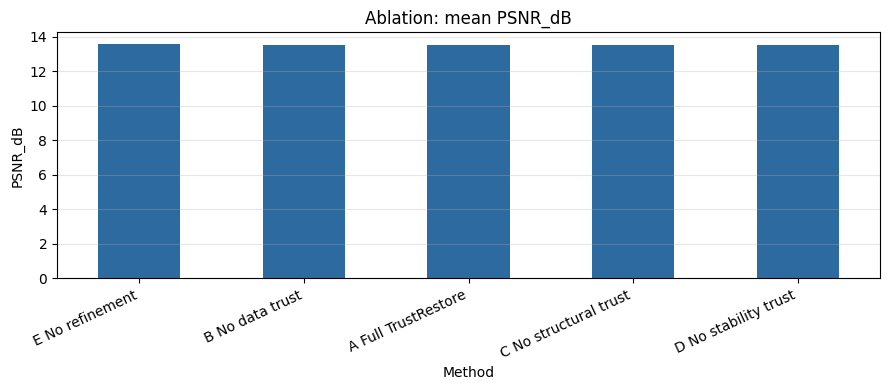

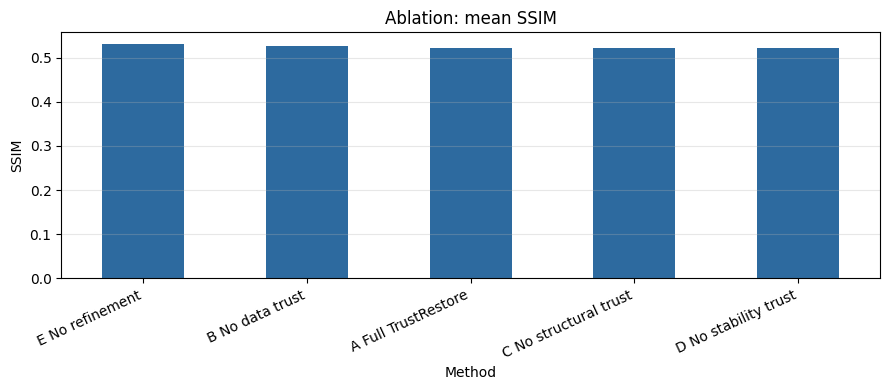

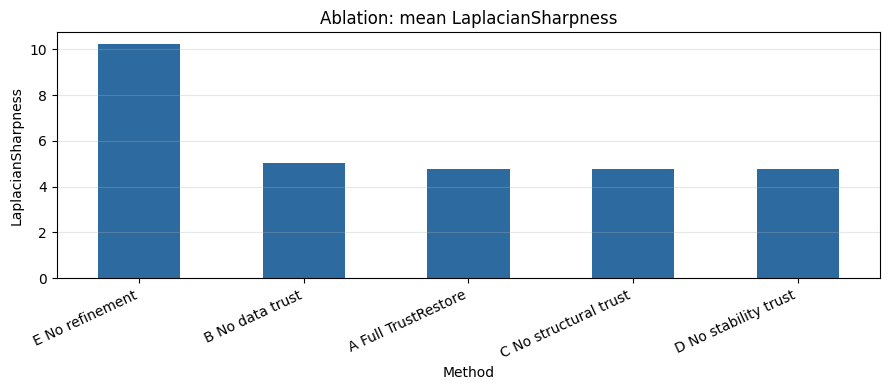

In [ ]:
# Ablation experiment
ablation_rows=[]
for i,r in enumerate(results,1):
    variants={}
    t,_,_,_=trust_map(r['degraded'],r['restored'],r['var']); variants['A Full TrustRestore']=refine(r['restored'],t)
    t,_,_,_=trust_map(r['degraded'],r['restored'],r['var'],use_data=False); variants['B No data trust']=refine(r['restored'],t)
    t,_,_,_=trust_map(r['degraded'],r['restored'],r['var'],use_structure=False); variants['C No structural trust']=refine(r['restored'],t)
    t,_,_,_=trust_map(r['degraded'],r['restored'],r['var'],use_stability=False); variants['D No stability trust']=refine(r['restored'],t)
    variants['E No refinement']=r['restored']
    for name,out in variants.items():
        ablation_rows.append({'Image':i,'Method':name,'PSNR_dB':psnr(r['clean'],out,data_range=1.0),'SSIM':ssim(r['clean'],out,channel_axis=2,data_range=1.0),'LaplacianSharpness':sharpness(out)})
ablation_df=pd.DataFrame(ablation_rows); ablation_df.to_csv('research_analysis/table_ablation.csv',index=False); display(ablation_df.round(4))
for metric in ['PSNR_dB','SSIM','LaplacianSharpness']:
    values=ablation_df.groupby('Method')[metric].mean().sort_values(ascending=False)
    plt.figure(figsize=(9,4)); values.plot(kind='bar',color='#2D6A9F'); plt.ylabel(metric); plt.title(f'Ablation: mean {metric}'); plt.xticks(rotation=25,ha='right'); plt.grid(axis='y',alpha=.3); plt.tight_layout()
    plt.savefig(f'paper_figures/fig7_ablation_{metric}.png',dpi=300,bbox_inches='tight'); plt.show()

In [ ]:
# Save all outputs
for i,r in enumerate(results,1):
    for name,image in [('clean',r['clean']),('degraded',r['degraded']),('restored',r['restored']),('refined',r['refined'])]:
        cv2.imwrite(f'paper_outputs/image{i}_{name}.png',cv2.cvtColor((np.clip(image,0,1)*255).astype(np.uint8),cv2.COLOR_RGB2BGR))
    cv2.imwrite(f'paper_outputs/image{i}_trust_map.png',(r['trust'][...,0]*255).astype(np.uint8))
with zipfile.ZipFile('TrustRestore_v2_outputs.zip','w',zipfile.ZIP_DEFLATED) as z:
    for folder in ['paper_figures','paper_outputs','research_analysis','saved_model']:
        for root,_,names in os.walk(folder):
            for name in names: z.write(os.path.join(root,name))
files.download('TrustRestore_v2_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Optional Gradio Web Interface
Run after training. It accepts any image and returns restoration, Trust Map, and trust-refined output. No PSNR/SSIM is reported because uploaded real images have no clean reference.

In [ ]:
def web_process(image,threshold):
    if image is None: return None,None,None
    image=image.astype(np.float32)/255.0; h,w=image.shape[:2]; scale=min(1.0,MAX_SIZE/max(h,w))
    if scale<1: image=cv2.resize(image,(int(w*scale),int(h*scale)),interpolation=cv2.INTER_AREA)
    restored,var=mc_predict(model,image); trust,_,_,_=trust_map(image,restored,var); final=refine(restored,trust,float(threshold))
    color=(plt.get_cmap('jet')(trust[...,0])[:,:,:3]*255).astype(np.uint8)
    return (restored*255).astype(np.uint8),color,(final*255).astype(np.uint8)
app=gr.Interface(fn=web_process,inputs=[gr.Image(type='numpy',label='Upload image'),gr.Slider(0.1,0.9,value=.45,step=.05,label='Low-trust threshold')],outputs=[gr.Image(label='Deep restoration'),gr.Image(label='Trust Map'),gr.Image(label='Trust-refined output')],title='TrustRestore v2: Trust-Aware Image Restoration',description='Preliminary research demo: upload an image to generate restoration and per-pixel trust visualization.')
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ac430644876f5a5d27.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
